# IDENTIFICACIÓN DE CARRILES Y LIMPIEZA DE RUIDO - VISTA LATERAL DENTRO DEL AGUA (ILP)

Juan David Hurtado Molano

Laura Sofía Salamanca Barrera

Esta vista es ILP, la cámara sumergida mirando de costado. Hay que identificar los carriles con Hough y quitar lo demás. Al final queda la imagen sobre fondo negro: sin el agua y sin el ruido, con las corcheras marcadas. Los nadadores se dejan entre los carriles.

Las funciones reciben la máscara de agua como parámetro. Cuando se pase a IL o a ISL se cambia esa máscara y no el resto.

Las corcheras y las guías del fondo son paralelas en la piscina, todas corren a lo largo. En la foto, por la perspectiva, esas paralelas se cortan en un solo punto, el punto de fuga. Una recta de Hough se toma como carril si pasa por ese punto.

Ese punto sale de cruzar las rectas de Hough. En coordenadas homogéneas la intersección de dos rectas es el producto cruz. Ya con el punto, cada carril es una recta que nace ahí, y la piscina queda entre las rectas de los extremos, cortadas con el borde de la imagen.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "images").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import detector_color as dc  # máscara de agua de la primera entrega

VISTA = "ILP"
RUTAS = sorted((ROOT / "data" / "images" / VISTA).glob("*.jpg"))
SALIDA = ROOT / "output" / "corcheras" / VISTA
segmentar_agua = dc.segmentar_ilp      # esto es lo que cambia por vista

plt.rcParams["figure.dpi"] = 60   # figuras más chicas dentro del notebook
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)


def mostrar(imagenes, titulos, ancho=6.4, cmap="gray"):
    fig, ax = plt.subplots(1, len(imagenes), figsize=(ancho * len(imagenes), ancho * 0.6))
    ax = np.atleast_1d(ax)
    for a, im, t in zip(ax, imagenes, titulos):
        a.imshow(rgb(im) if im.ndim == 3 else im, cmap=cmap)
        a.set_title(t, fontsize=11); a.axis("off")
    plt.tight_layout(); plt.show()


print(f"{VISTA}: {len(RUTAS)} imágenes")


ILP: 20 imágenes


## Parámetros

Están todos juntos. Los que dependen de la resolución están pensados para 1920×1080.


In [2]:
PARAMS = dict(
    # limpieza de la máscara antes de Canny
    area_min_ruido=600,        # px: manchas de no-agua más chicas se rellenan como agua
    canny_bajo=50, canny_alto=150,
    # Hough probabilística
    hough_umbral=60, hough_long_min=80, hough_hueco_max=30,
    # punto de fuga
    vp_tolerancia=1.5,         # grados: cuánto puede desviarse un segmento de apuntar al VP
    vp_iteraciones=800,
    # agrupación de rectas de carril
    gap_grupo=12,              # px (medidos sobre la recta de referencia)
    soporte_min=0.40,          # fracción de la recta que debe caer sobre no-agua
    # bandas de ruido
    radio_perfil=160, margen_banda=1.25, extra_banda=3,
)

Tres imágenes cubren los casos de esta vista.

* ILP_00925: las corcheras van en diagonal y el punto de fuga cae fuera de la imagen. Es el caso más común.
* ILP_01295: además de los carriles se ven las marcas en T de la pared. Son otra familia de rectas.
* ILP_02405: la cámara queda casi paralela a las corcheras. El punto de fuga se va prácticamente al infinito y en la foto las rectas se ven casi paralelas.


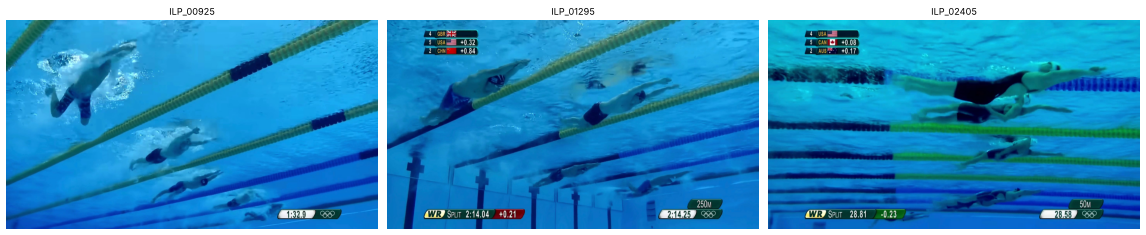

In [3]:
EJEMPLOS = ["ILP_00925", "ILP_01295", "ILP_02405"]
frames = {n: cv2.imread(str(ROOT / "data" / "images" / VISTA / f"{n}.jpg")) for n in EJEMPLOS}
mostrar(list(frames.values()), EJEMPLOS)

## Gráficos de la transmisión

El marcador, los tiempos y el logo no son piscina, pero sus recuadros son bordes rectos y Hough los agarra. En vez de recortar posiciones a mano, se sacan del propio conjunto de imágenes.

Un borde que cae en el mismo píxel en varias fotos no puede ser agua, ni corchera, ni nadador, porque eso se mueve entre tomas. Lo único que se queda quieto es el gráfico puesto encima. Se acumulan los bordes de Canny de los 20 frames, se cierran los contornos que aparecen en 3 o más, y se rellenan los que tienen forma de recuadro.


In [4]:
def mascara_graficos(rutas, canny=(80, 200), min_frames=3):
    """Gráficos de la transmisión (marcador, tiempos, logos) aprendidos del propio conjunto.

    Un borde que aparece EXACTAMENTE en el mismo píxel en varios frames distintos no puede
    ser agua, corchera ni nadador (todo eso se mueve con la cámara): es un gráfico superpuesto.
    Se acumulan los bordes de Canny de todos los frames, se cierran los contornos persistentes
    y se rellenan los que tienen forma de recuadro (horizontales, compactos).
    """
    acumulado = None
    for ruta in rutas:
        gris = cv2.cvtColor(cv2.imread(str(ruta)), cv2.COLOR_BGR2GRAY)
        bordes = (cv2.Canny(gris, *canny) > 0).astype(np.int32)
        acumulado = bordes if acumulado is None else acumulado + bordes
    persistente = ((acumulado >= min_frames) * 255).astype(np.uint8)
    persistente = cv2.morphologyEx(persistente, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    contornos, _ = cv2.findContours(persistente, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    graficos = np.zeros_like(persistente)
    for c in contornos:
        x, y, w, h = cv2.boundingRect(c)
        area = cv2.contourArea(c)
        if w * h < 1500 or h < 15:
            continue
        solidez = area / max(cv2.contourArea(cv2.convexHull(c)), 1)
        if area / (w * h) > 0.5 and solidez > 0.6 and w > 1.5 * h:
            cv2.drawContours(graficos, [c], -1, 255, -1)
    return cv2.dilate(graficos, np.ones((9, 9), np.uint8)), persistente

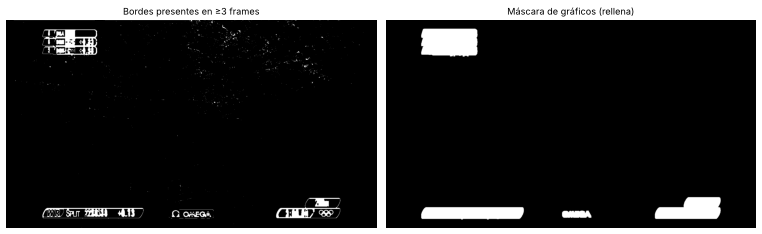

In [5]:
GRAFICOS, persistentes = mascara_graficos(RUTAS)
mostrar([persistentes, GRAFICOS], ["Bordes presentes en ≥3 frames", "Máscara de gráficos (rellena)"])

## Máscara de agua

Se parte de `segmentar_ilp`: H entre 90 y 110, más saturación, más un brillo relativo al agua de cada imagen. Antes de Canny se limpia en dos cosas.

Los gráficos se pintan como agua, para que no generen borde. Las manchas chicas que no son agua, burbujas y reflejos de menos de `area_min_ruido` px, también se pintan como agua.

Lo que queda son las fronteras de los objetos grandes: corcheras, guías, nadadores y marcas.


In [6]:
def limpiar_mascara(agua, graficos, area_min):
    """Prepara la máscara de agua para Canny: los gráficos y las manchas chicas pasan a ser agua."""
    limpia = agua.copy()
    limpia[graficos > 0] = 255
    no_agua = cv2.bitwise_not(limpia)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(no_agua, connectivity=8)
    chicas = np.where(stats[:, cv2.CC_STAT_AREA] < area_min)[0]
    limpia[np.isin(etiquetas, chicas) & (etiquetas > 0)] = 255
    return limpia

## Hough

Se corre `HoughLinesP` sobre los bordes ya limpios. Los parámetros van amplios a propósito, umbral bajo y hueco grande. El borde de la corchera es ondulado por los flotadores y no conviene perder ninguna. Lo que entre de más lo filtra el punto de fuga.

Cada segmento se pasa a coordenadas homogéneas. La recta que une dos puntos $(x, y, 1)$ es el producto cruz de esos puntos. Cruzar dos rectas es otro producto cruz, y sirve aunque el cruce quede fuera de la imagen. Si las rectas son paralelas, la tercera coordenada da 0 y el cruce se va al infinito.


In [7]:
def segmentos_hough(bordes, p):
    L = cv2.HoughLinesP(bordes, 1, np.pi / 180, p["hough_umbral"],
                        minLineLength=p["hough_long_min"], maxLineGap=p["hough_hueco_max"])
    return np.zeros((0, 4)) if L is None else L.reshape(-1, 4).astype(float)


def longitudes(S):
    return np.hypot(S[:, 2] - S[:, 0], S[:, 3] - S[:, 1])

### Canny sobre la máscara y sobre el gris

En ILP_01665, que tiene mucha espuma, se ve la diferencia. Sobre el gris cada burbuja y cada reflejo es un borde, y Hough devuelve cientos de segmentos cortos. Sobre la máscara limpia el agua es un bloque sin textura. Los bordes que quedan son contornos de objetos grandes: corcheras, guías y nadadores.

La comparación con las 20 imágenes está más abajo, cuando ya se tiene el punto de fuga y se puede medir qué segmentos son carril.


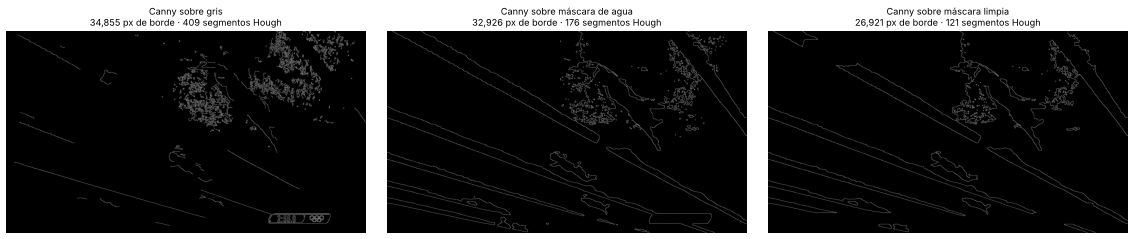

In [8]:
frame = cv2.imread(str(ROOT / "data" / "images" / VISTA / "ILP_01665.jpg"))   # toma con mucha espuma
gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
agua = segmentar_agua(frame)
limpia = limpiar_mascara(agua, GRAFICOS, PARAMS["area_min_ruido"])

canny_gris = cv2.Canny(cv2.GaussianBlur(gris, (5, 5), 0), PARAMS["canny_bajo"], PARAMS["canny_alto"])
canny_agua = cv2.Canny(cv2.GaussianBlur(agua, (5, 5), 0), PARAMS["canny_bajo"], PARAMS["canny_alto"])
canny_limpia = cv2.Canny(cv2.GaussianBlur(limpia, (5, 5), 0), PARAMS["canny_bajo"], PARAMS["canny_alto"])

titulos = []
for nombre, b in [("Canny sobre gris", canny_gris), ("Canny sobre máscara de agua", canny_agua),
                  ("Canny sobre máscara limpia", canny_limpia)]:
    n_seg = len(segmentos_hough(b, PARAMS))
    titulos.append(f"{nombre}\n{int((b > 0).sum()):,} px de borde · {n_seg} segmentos Hough")
mostrar([canny_gris, canny_agua, canny_limpia], titulos)

## Punto de fuga

Se toman dos segmentos al azar. Los largos tienen más chance de salir. Su intersección es un candidato a punto de fuga. Cada segmento vota por ese candidato si, al prolongarlo, apunta hacia él, con un error angular menor que `vp_tolerancia`. El voto vale la longitud del segmento. Después de 800 intentos se queda el candidato con más votos y se ajusta por mínimos cuadrados con los segmentos que votaron por él.

Los que no apuntan a ese punto son contornos de nadadores, espuma, marcas de la pared o gráficos. Esos no se toman como carril.

En la entrega anterior se filtraba por ángulo. Acá no alcanza, porque en ILP las corcheras pueden verse horizontales, en diagonal o casi verticales, según la toma.


In [9]:
def a_homogeneas(S):
    """Recta homogénea de cada segmento: l = p1 × p2, normalizada para que (a, b) sea unitario."""
    p1 = np.c_[S[:, :2], np.ones(len(S))]
    p2 = np.c_[S[:, 2:], np.ones(len(S))]
    l = np.cross(p1, p2)
    return l / np.linalg.norm(l[:, :2], axis=1, keepdims=True)


def error_angular(S, l, vp):
    """Ángulo (grados) entre cada segmento y la recta que une su punto medio con el VP.

    Funciona igual si el VP es finito (w≠0) o si está en el infinito (w=0, rectas paralelas
    en la imagen): todo se hace con productos cruz en coordenadas homogéneas.
    """
    medio = np.c_[(S[:, :2] + S[:, 2:]) / 2, np.ones(len(S))]
    hacia_vp = np.cross(medio, vp)
    hacia_vp = hacia_vp[:, :2] / np.maximum(np.linalg.norm(hacia_vp[:, :2], axis=1), 1e-9)[:, None]
    coseno = np.abs((hacia_vp * l[:, :2]).sum(1))
    return np.degrees(np.arccos(np.clip(coseno, 0, 1)))


def punto_de_fuga(S, tol=1.5, iteraciones=800, semilla=0):
    """RANSAC sobre intersecciones de pares de segmentos (l_i × l_j).

    Cada candidato a VP se puntúa con la longitud total de los segmentos que apuntan hacia él.
    El ganador se refina por mínimos cuadrados: el v que minimiza Σ w_i (l_i · v)^2 es el
    autovector de menor autovalor de Σ w_i l_i l_iᵀ.
    """
    rng = np.random.default_rng(semilla)
    l = a_homogeneas(S); w = longitudes(S); prob = w / w.sum()
    mejor_puntaje, mejor_vp = -1, None
    for _ in range(iteraciones):
        i, j = rng.choice(len(S), 2, replace=False, p=prob)
        vp = np.cross(l[i], l[j])
        if np.linalg.norm(vp) < 1e-12:
            continue
        vp /= np.linalg.norm(vp)
        puntaje = w[error_angular(S, l, vp) < tol].sum()
        if puntaje > mejor_puntaje:
            mejor_puntaje, mejor_vp = puntaje, vp
    inliers = error_angular(S, l, mejor_vp) < tol
    M = (l[inliers] * w[inliers, None]).T @ l[inliers]
    vp = np.linalg.eigh(M)[1][:, 0]
    inliers = error_angular(S, l, vp) < tol
    return vp, inliers, mejor_puntaje / w.sum()


def es_finito(vp):
    return abs(vp[2]) > 1e-6 * np.linalg.norm(vp[:2])


def vp_cartesiano(vp):
    return vp[:2] / vp[2] if es_finito(vp) else None

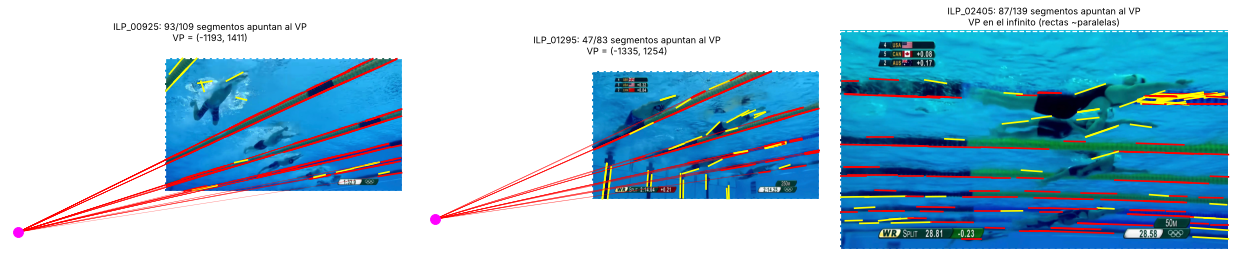

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(21, 6))
for a, (nombre, frame) in zip(ax, frames.items()):
    agua = segmentar_agua(frame)
    limpia = limpiar_mascara(agua, GRAFICOS, PARAMS["area_min_ruido"])
    bordes = cv2.Canny(cv2.GaussianBlur(limpia, (5, 5), 0), PARAMS["canny_bajo"], PARAMS["canny_alto"])
    S = segmentos_hough(bordes, PARAMS)
    vp, inl, frac = punto_de_fuga(S, PARAMS["vp_tolerancia"], PARAMS["vp_iteraciones"])
    h, w = frame.shape[:2]
    a.imshow(rgb(frame))
    v = vp_cartesiano(vp)
    for (x1, y1, x2, y2), k in zip(S, inl):
        if k and v is not None and np.hypot(*(v - [w / 2, h / 2])) < 4 * w:
            m = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
            a.plot([m[0], v[0]], [m[1], v[1]], color="red", lw=0.5, alpha=0.5)  # prolongación hasta el VP
        a.plot([x1, x2], [y1, y2], color="red" if k else "yellow", lw=2)
    texto = "VP en el infinito (rectas ~paralelas)"
    if v is not None and np.hypot(*(v - [w / 2, h / 2])) < 4 * w:
        a.plot(*v, "o", color="magenta", ms=12)
        xs, ys = [0, w, v[0]], [0, h, v[1]]
        a.set_xlim(min(xs) - 100, max(xs) + 100); a.set_ylim(max(ys) + 100, min(ys) - 100)
        texto = f"VP = ({v[0]:.0f}, {v[1]:.0f})"
    a.add_patch(plt.Rectangle((0, 0), w, h, fill=False, ec="white", lw=1.5, ls="--"))
    a.set_title(f"{nombre}: {inl.sum()}/{len(S)} segmentos apuntan al VP\n{texto}", fontsize=11)
    a.axis("off")
plt.tight_layout(); plt.show()

En rojo van los segmentos que apuntan al punto de fuga, los carriles. En amarillo, los que se descartan: nadadores, marcas y espuma. El recuadro punteado es el borde de la imagen. El punto casi siempre cae afuera, por eso se usa la recta completa: con el pedazo que se ve no se halla el cruce.


### La máscara en las 20 imágenes

Se mide qué fracción de la longitud de los segmentos de Hough apunta al punto de fuga. Si esa fracción es alta, hay menos rectas que no son carril. Se compara el Canny del gris, el de la máscara de agua sin limpiar y el de la máscara limpia.


In [11]:
filas = []
for ruta in RUTAS:
    frame = cv2.imread(str(ruta))
    agua = segmentar_agua(frame)
    fuentes = {"gris": cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), "máscara": agua,
               "máscara limpia": limpiar_mascara(agua, GRAFICOS, PARAMS["area_min_ruido"])}
    fila = [ruta.stem]
    for im in fuentes.values():
        b = cv2.Canny(cv2.GaussianBlur(im, (5, 5), 0), PARAMS["canny_bajo"], PARAMS["canny_alto"])
        S = segmentos_hough(b, PARAMS)
        fila.append(punto_de_fuga(S, PARAMS["vp_tolerancia"], PARAMS["vp_iteraciones"])[2] if len(S) >= 3 else 0.0)
    filas.append(fila)

print(f"{'imagen':<11}{'gris':>8}{'máscara':>10}{'limpia':>9}")
for f in filas:
    print(f"{f[0]:<11}{f[1]:>8.2f}{f[2]:>10.2f}{f[3]:>9.2f}")
M = np.array([f[1:] for f in filas])
print(f"{'promedio':<11}{M[:, 0].mean():>8.2f}{M[:, 1].mean():>10.2f}{M[:, 2].mean():>9.2f}")
print(f"{'peor caso':<11}{M[:, 0].min():>8.2f}{M[:, 1].min():>10.2f}{M[:, 2].min():>9.2f}")

imagen         gris   máscara   limpia
ILP_00185      0.82      0.86     0.91
ILP_00370      0.93      0.75     0.75
ILP_00555      0.19      0.51     0.64
ILP_00740      0.69      0.61     0.65
ILP_00925      0.36      0.87     0.94
ILP_01110      0.26      0.49     0.68
ILP_01295      0.75      0.69     0.68
ILP_01480      0.56      0.32     0.54
ILP_01665      0.17      0.54     0.68
ILP_01850      0.44      0.53     0.66
ILP_02035      0.50      0.79     0.83
ILP_02220      0.55      0.84     0.91
ILP_02405      0.89      0.62     0.68
ILP_02590      0.86      0.72     0.86
ILP_02775      0.88      0.38     0.50
ILP_02960      0.75      0.55     0.53
ILP_03145      0.96      0.46     0.47
ILP_03330      0.58      0.63     0.69
ILP_03515      0.31      0.61     0.78
ILP_03700      0.37      0.69     0.77
promedio       0.59      0.62     0.71
peor caso      0.17      0.32     0.47


La máscara limpia no gana en todas. En tomas sin espuma y con las corcheras bien contrastadas (ILP_00370, 02405, 02775, 03145) el gris funciona igual o mejor. En las tomas con espuma (ILP_00555, 00925, 01110, 01665, 03515) el gris baja a 17-36% y la máscara limpia se queda entre 64% y 94%.

Por eso se sigue con la máscara limpia. El promedio es mejor y, sobre todo, el peor caso no se cae tanto. Si el peor caso es muy bajo, el RANSAC puede quedarse con un punto de fuga que no es.


## Rectas de carril

Con el punto de fuga, cada recta de carril queda en un solo número: dónde corta una recta de referencia que pasa por el centro de la imagen, perpendicular a la dirección hacia el punto. Así el problema pasa de dos dimensiones a una.

Cada segmento que votó por el punto se fuerza a pasar por él y se le calcula una posición. Las posiciones cercanas se juntan, con `gap_grupo`. Los pedazos de una misma corchera caen en el mismo grupo.

Una corchera gruesa tiene borde de arriba y borde de abajo, entonces da dos grupos. Se fusionan si la recta del medio cae sobre lo que no es agua, porque eso es el cuerpo de la corchera.

Para aceptar la recta como carril tiene que haber corchera o guía debajo en al menos `soporte_min` de lo que se alcanza a ver. Un contorno de nadador que por casualidad apunta al punto de fuga no pasa eso.

La recta se recorta a la imagen cortándola con los cuatro bordes.


In [12]:
def referencia(vp, shape):
    """Recta de referencia: pasa por el centro de la imagen, perpendicular a la dirección centro→VP.
    Toda recta que pasa por el VP la corta en un único punto: esa posición t (en px) la identifica."""
    h, w = shape[:2]
    c = np.array([w / 2, h / 2, 1.0])
    d = (vp[:2] / vp[2] - c[:2]) if es_finito(vp) else vp[:2].copy()
    d /= np.linalg.norm(d)
    n = np.array([-d[1], d[0]])
    return np.cross(c, np.r_[c[:2] + n, 1.0]), c, n


def posicion_t(S, vp, shape):
    """Fuerza cada segmento a pasar por el VP (recta VP–punto medio) y devuelve su posición t."""
    medio = np.c_[(S[:, :2] + S[:, 2:]) / 2, np.ones(len(S))]
    rectas = np.cross(medio, vp)
    lref, c, n = referencia(vp, shape)
    X = np.cross(rectas, lref)
    X = X[:, :2] / X[:, 2:3]
    return (X - c[:2]) @ n


def recta_desde_t(t, vp, shape):
    lref, c, n = referencia(vp, shape)
    p = np.r_[c[:2] + t * n, 1.0]
    l = np.cross(p, vp)
    return l / np.linalg.norm(l[:2])


BORDES_IMAGEN = lambda w, h: [np.array([1, 0, 0.]), np.array([1, 0, -(w - 1.)]),
                              np.array([0, 1, 0.]), np.array([0, 1, -(h - 1.)])]


def recortar_a_imagen(l, shape):
    """Recta infinita → segmento visible: intersección (l × borde) con los 4 bordes de la imagen."""
    h, w = shape[:2]
    puntos = []
    for b in BORDES_IMAGEN(w, h):
        X = np.cross(l, b)
        if abs(X[2]) < 1e-12:
            continue
        x, y = X[:2] / X[2]
        if -1 <= x <= w and -1 <= y <= h:
            puntos.append((round(x, 1), round(y, 1)))
    puntos = sorted(set(puntos))
    return None if len(puntos) < 2 else (np.array(puntos[0]), np.array(puntos[-1]))


def muestrear(l, shape, n):
    seg = recortar_a_imagen(l, shape)
    if seg is None:
        return np.zeros((0, 2))
    s = np.linspace(0.02, 0.98, n)[:, None]
    return seg[0] + s * (seg[1] - seg[0])


def fraccion_sobre_no_agua(l, no_agua, shape, n=200):
    P = muestrear(l, shape, n).astype(int)
    return 0.0 if len(P) == 0 else float((no_agua[P[:, 1], P[:, 0]] > 0).mean())


def agrupar_1d(t, gap):
    orden = np.argsort(t)
    grupos = [[orden[0]]]
    for a, b in zip(orden[:-1], orden[1:]):
        if t[b] - t[a] > gap:
            grupos.append([b])
        else:
            grupos[-1].append(b)
    return [np.array(g) for g in grupos]

## Dónde termina la piscina

La zona de carriles es lo que queda entre las dos rectas de los extremos. La corchera más cercana a la cámara suele quedar fuera del cuadro, así que cada extremo se abre un espaciado de carril más, el último que se midió de ese lado. Si no, se corta al nadador del carril de más cerca.

Cuando el punto de fuga es finito, esa zona es un sector que sale del punto. Cuando el punto se va al infinito, queda una franja entre dos paralelas.

El polígono sale de cortar esa zona con el rectángulo de la imagen (`cv2.intersectConvexConvex`). Los vértices son los cruces de las rectas extremas con los bordes de la foto, y el punto de fuga si cae adentro.

Entre los segmentos descartados también se busca otra familia: las marcas en T de la pared. En la piscina son verticales y se juntan en otro punto. Se aceptan si el grupo es coherente, casi vertical, y va en una dirección distinta a la de los carriles.


In [13]:
def poligono_piscina(t_min, t_max, vp, shape, grande=20000.0):
    """Región entre las dos rectas límite, recortada a la imagen por intersección de convexos.

    VP finito  → sector triangular con vértice en el VP.
    VP infinito → franja entre dos rectas paralelas.
    """
    h, w = shape[:2]
    rect = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]).reshape(-1, 1, 2)
    _, c, n = referencia(vp, shape)
    l1, l2 = recta_desde_t(t_min, vp, shape), recta_desde_t(t_max, vp, shape)
    if es_finito(vp):
        v = vp_cartesiano(vp)
        grande = max(grande, 3 * np.linalg.norm(v - c[:2]))   # los rayos deben alcanzar la imagen
        P = [v]
        for l in (l1, l2):
            u = np.array([l[1], -l[0]]); u /= np.linalg.norm(u)
            if u @ (c[:2] - v) < 0:
                u = -u
            P.append(v + grande * u)
    else:
        u = np.array([l1[1], -l1[0]]); u /= np.linalg.norm(u)
        p1, p2 = c[:2] + t_min * n, c[:2] + t_max * n
        P = [p1 - grande * u, p1 + grande * u, p2 + grande * u, p2 - grande * u]
    casco = cv2.convexHull(np.float32(P))
    _, inter = cv2.intersectConvexConvex(casco, rect)
    return None if inter is None else inter.reshape(-1, 2)


def familia_transversal(S, inliers, min_seg=3, tol=2.0, dif_min=30, max_desvio_vertical=25):
    """Segunda familia de rectas entre los descartados: marcas verticales de la pared (las T)."""
    resto = S[~inliers]
    if len(resto) < min_seg:
        return None
    _, in2, _ = punto_de_fuga(resto, tol=tol, iteraciones=400)
    if in2.sum() < min_seg:
        return None
    angulo = lambda X: np.degrees(np.arctan2(X[:, 3] - X[:, 1], X[:, 2] - X[:, 0])) % 180
    dif = abs((np.median(angulo(S[inliers])) - np.median(angulo(resto[in2])) + 90) % 180 - 90)
    # las marcas de la pared son verticales en el mundo; con la cámara derecha, casi verticales en la imagen
    casi_vertical = abs(np.median(angulo(resto[in2])) - 90) <= max_desvio_vertical
    return resto[in2] if (dif >= dif_min and casi_vertical) else None

## Ancho de la corchera

Para cada recta se mide el ancho de la corchera o de la guía. Son perfiles perpendiculares en 60 puntos. De cada uno se toma el tramo continuo de no-agua que toca la recta, y después la mediana de esos anchos. Si en un punto hay un nadador tapando la corchera, la mediana no se mueve por ese punto.

Una corchera de ancho constante se ve más gruesa cerca de la cámara. Si ese ancho se divide por la distancia al punto de fuga, queda constante. La banda que se marca entonces no es un rectángulo: es una cuña que nace en el punto de fuga. Con el punto en el infinito, la cuña se vuelve una franja de ancho fijo.

Dentro de la banda solo se dejan los píxeles que no son agua. La corchera sale con la forma que tiene, flotadores incluidos.


In [14]:
def medir_banda(l, vp, no_agua, shape, R=160, tol=4, n=60):
    """Ancho real del objeto (corchera/guía) que genera la recta.

    En n puntos a lo largo de la recta se toma un perfil perpendicular y se mide el tramo
    continuo de no-agua que la toca. Los offsets se dividen por la distancia al VP: en
    perspectiva, una corchera de ancho físico constante se ve como una CUÑA que nace en el VP
    (más ancha cerca de la cámara). Con VP en el infinito, la banda es de ancho constante.
    Devuelve (offset_izq, offset_der, fracción de puntos con soporte) o None.
    """
    h, w = no_agua.shape
    normal = l[:2] / np.linalg.norm(l[:2])
    v = vp_cartesiano(vp)
    o = np.arange(-R, R + 1)
    izq, der = [], []
    P = muestrear(l, shape, n)
    for p in P:
        q = np.round(p[None, :] + o[:, None] * normal[None, :]).astype(int)
        dentro = (q[:, 0] >= 0) & (q[:, 0] < w) & (q[:, 1] >= 0) & (q[:, 1] < h)
        val = np.zeros(len(o), bool)
        val[dentro] = no_agua[q[dentro, 1], q[dentro, 0]] > 0
        cand = [i for i in range(R - tol, R + tol + 1) if val[i]]
        if not cand:
            continue
        a = b = min(cand, key=lambda i: abs(i - R))
        while a > 0 and val[a - 1]:
            a -= 1
        while b < 2 * R and val[b + 1]:
            b += 1
        if a == 0 or b == 2 * R:      # tramo saturado: nadador o espuma pegados a la recta
            continue
        d = np.linalg.norm(p - v) if v is not None else 1.0
        izq.append(o[a] / d); der.append(o[b] / d)
    if len(izq) < 5:
        return None
    return float(np.median(izq)), float(np.median(der)), len(izq) / max(len(P), 1)


def poligono_banda(l, vp, banda, shape, margen=1.25, extra=3):
    seg = recortar_a_imagen(l, shape)
    if seg is None:
        return None
    normal = l[:2] / np.linalg.norm(l[:2])
    v = vp_cartesiano(vp)
    centro = (banda[0] + banda[1]) / 2
    semiancho = (banda[1] - banda[0]) / 2 * margen
    d = [np.linalg.norm(p - v) if v is not None else 1.0 for p in seg]
    lado_a = [p + normal * ((centro - semiancho) * di - extra) for p, di in zip(seg, d)]
    lado_b = [p + normal * ((centro + semiancho) * di + extra) for p, di in zip(seg, d)]
    return np.array(lado_a + lado_b[::-1])

## Solo las corcheras

Corchera es lo que no es agua y cae dentro de las bandas de carril, sin contar los gráficos.

Lo demás que no es agua se quita: nadadores, espuma, burbujas, las marcas en T y la superficie.

La figura final no es solo la corchera. Es la imagen, sin el agua y sin el ruido (lo de afuera de la piscina, los gráficos, las marcas en T de la pared, las líneas guía del fondo y los puntos sueltos), más la recta de cada corchera en su color. Los nadadores se quedan.

La función recibe `segmentar_agua`. Para otra vista se le pasa la máscara de esa vista.


In [15]:
def delimitar_piscina(frame, segmentar_agua, graficos, p=PARAMS):
    """Pipeline completo para un frame. segmentar_agua: función frame → máscara (255 = agua)."""
    h, w = frame.shape[:2]
    r = {}
    agua = segmentar_agua(frame)
    limpia = limpiar_mascara(agua, graficos, p["area_min_ruido"])
    bordes = cv2.Canny(cv2.GaussianBlur(limpia, (5, 5), 0), p["canny_bajo"], p["canny_alto"])
    S = segmentos_hough(bordes, p)
    no_agua = cv2.bitwise_not(agua); no_agua[graficos > 0] = 0
    no_agua_limpia = cv2.bitwise_not(limpia)
    r.update(agua=agua, limpia=limpia, bordes=bordes, segmentos=S, no_agua=no_agua,
             vp=None, inliers=np.zeros(len(S), bool), lineas=[], marcas=None, piscina=None)

    bandas = np.zeros((h, w), np.uint8)
    if len(S) >= 3:
        vp, inl, _ = punto_de_fuga(S, p["vp_tolerancia"], p["vp_iteraciones"])
        r.update(vp=vp, inliers=inl)
        Si = S[inl]; wi = longitudes(Si)
        t = posicion_t(Si, vp, frame.shape)
        ts = sorted(float(np.average(t[g], weights=wi[g])) for g in agrupar_1d(t, p["gap_grupo"]))
        # los dos bordes de una misma corchera dan dos grupos: se fusionan si entre ellos hay no-agua
        fusion = [ts[0]]
        for tk in ts[1:]:
            medio = recta_desde_t((fusion[-1] + tk) / 2, vp, frame.shape)
            if tk - fusion[-1] < 120 and fraccion_sobre_no_agua(medio, no_agua_limpia, frame.shape) > 0.6:
                fusion[-1] = (fusion[-1] + tk) / 2
            else:
                fusion.append(tk)
        for tk in fusion:
            l = recta_desde_t(tk, vp, frame.shape)
            banda = medir_banda(l, vp, no_agua_limpia, frame.shape, R=p["radio_perfil"])
            if banda is None or banda[2] < p["soporte_min"]:
                continue   # la recta no tiene una corchera/guía detrás en casi toda su longitud
            poly = poligono_banda(l, vp, banda, frame.shape, p["margen_banda"], p["extra_banda"])
            if poly is None:
                continue
            cv2.fillPoly(bandas, [np.round(poly).astype(np.int32)], 255)
            r["lineas"].append(dict(t=tk, recta=l, banda=banda, poligono=poly))

        # marcas en T de la pared: no son corcheras, quedan como ruido
        r["marcas"] = familia_transversal(S, inl)

        if len(r["lineas"]) >= 3:
            ts = sorted(d["t"] for d in r["lineas"])
            r["piscina"] = poligono_piscina(ts[0] - (ts[1] - ts[0]), ts[-1] + (ts[-1] - ts[-2]), vp, frame.shape)

    # solo corchera o guía: no-agua dentro de las bandas
    r["corcheras"] = cv2.bitwise_and(no_agua, bandas)
    # lo demás que no es agua: nadadores, espuma, marcas, burbujas
    r["ruido"] = cv2.bitwise_and(no_agua, cv2.bitwise_not(r["corcheras"]))
    return r


In [16]:
def dibujar(frame, r, grosor=4, con_piscina=False):
    """Identificación de carriles: rectas infinitas (rojo). Opcional: polígono de la piscina (verde)."""
    vis = frame.copy()
    if con_piscina and r["piscina"] is not None:
        cv2.polylines(vis, [np.round(r["piscina"]).astype(np.int32)], True, (0, 255, 0), grosor + 2)
    for d in r["lineas"]:
        a, b = recortar_a_imagen(d["recta"], frame.shape)
        cv2.line(vis, tuple(a.astype(int)), tuple(b.astype(int)), (0, 0, 255), grosor)
    v = vp_cartesiano(r["vp"]) if r["vp"] is not None else None
    if v is not None and 0 <= v[0] < frame.shape[1] and 0 <= v[1] < frame.shape[0]:
        cv2.circle(vis, tuple(v.astype(int)), 15, (0, 255, 255), -1)
    return vis


def solo(frame, mascara):
    """Píxeles originales donde la máscara está encendida, negro en el resto."""
    return cv2.bitwise_and(frame, frame, mask=mascara)
def color_de_corchera(frame, poligono, no_agua):
    """Tono de la franja, para pintar la recta del mismo color de la corchera."""
    if poligono is None:
        return (255, 255, 255)
    m = np.zeros(frame.shape[:2], np.uint8)
    cv2.fillPoly(m, [np.round(poligono).astype(np.int32)], 255)
    sel = m > 0
    if sel.sum() < 40:
        return (255, 255, 255)
    h = np.median(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)[..., 0][sel])
    # bajo el agua el amarillo queda cerca de H 90; el azul, un poco mas arriba
    if h < 103:
        return (0, 210, 255)
    return (255, 90, 0)


def mascara_marcas(marcas, shape, grosor=15):
    m = np.zeros(shape[:2], np.uint8)
    if marcas is None:
        return m
    for x1, y1, x2, y2 in marcas:
        cv2.line(m, (int(x1), int(y1)), (int(x2), int(y2)), 255, grosor)
    return m


def resultado(frame, r, a_min=40):
    """Imagen - agua - ruido, con la recta de cada corchera.
    Se quedan las corcheras y los nadadores."""
    h, w = frame.shape[:2]
    dentro = np.zeros((h, w), np.uint8)
    if r["piscina"] is not None:
        cv2.fillPoly(dentro, [np.round(r["piscina"]).astype(np.int32)], 255)
    else:
        dentro[:] = 255
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    H, S, V = cv2.split(hsv)
    # líneas guía del fondo: azul oscuro, y no son la corchera
    guia = (((H >= 110) & (H <= 128) & (S > 100) & (V < 130)).astype(np.uint8) * 255)
    guia = cv2.bitwise_and(guia, cv2.bitwise_not(r["corcheras"]))
    limpia = cv2.bitwise_and(r["no_agua"], dentro)
    limpia = cv2.bitwise_and(limpia, cv2.bitwise_not(guia))
    limpia = cv2.bitwise_and(limpia, cv2.bitwise_not(mascara_marcas(r["marcas"], frame.shape)))
    n, lab, st, _ = cv2.connectedComponentsWithStats(limpia)
    if n > 1:
        limpia[np.isin(lab, np.flatnonzero(st[:, 4] < a_min))] = 0
    out = np.zeros_like(frame)
    for d in r["lineas"]:
        if d["poligono"] is None:
            continue
        color = color_de_corchera(frame, d["poligono"], r["no_agua"])
        cv2.fillPoly(out, [np.round(d["poligono"]).astype(np.int32)], color)
    out[limpia > 0] = frame[limpia > 0]
    return out


### En las imágenes de referencia

A la izquierda está todo lo que no es agua, antes de limpiar. Al centro, las rectas de carril. A la derecha, la imagen sin agua y sin ruido, con las corcheras marcadas.


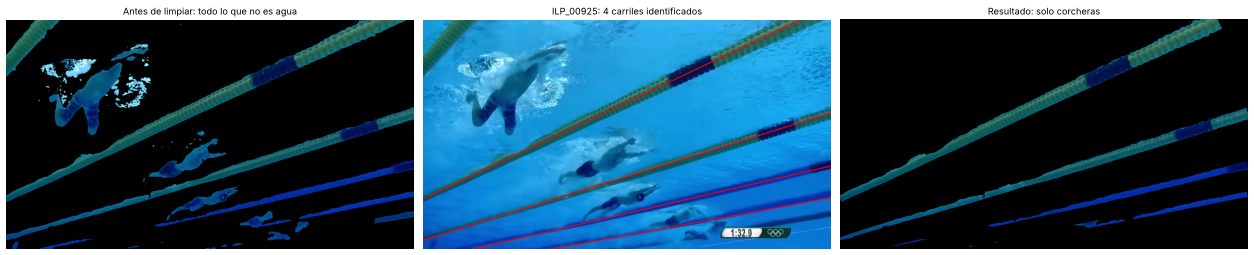

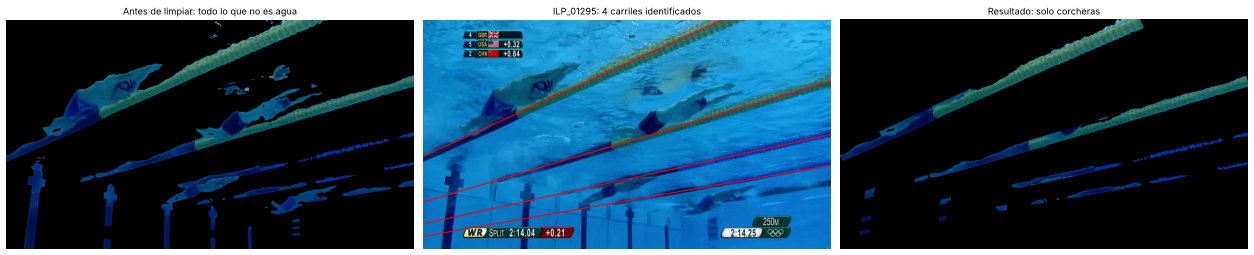

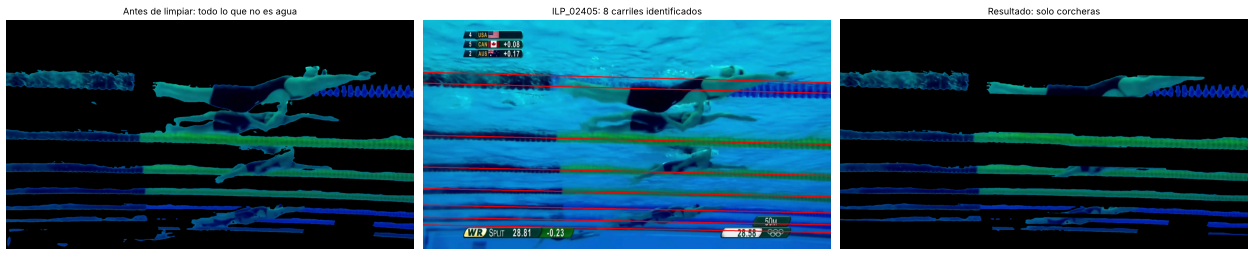

In [17]:
for nombre, frame in frames.items():
    r = delimitar_piscina(frame, segmentar_agua, GRAFICOS)
    mostrar([solo(frame, r["no_agua"]), dibujar(frame, r), resultado(frame, r)],
            ["Antes de limpiar: todo lo que no es agua", f"{nombre}: {len(r['lineas'])} carriles identificados",
             "Sin agua, sin ruido, corcheras marcadas"], ancho=7)


### En una imagen


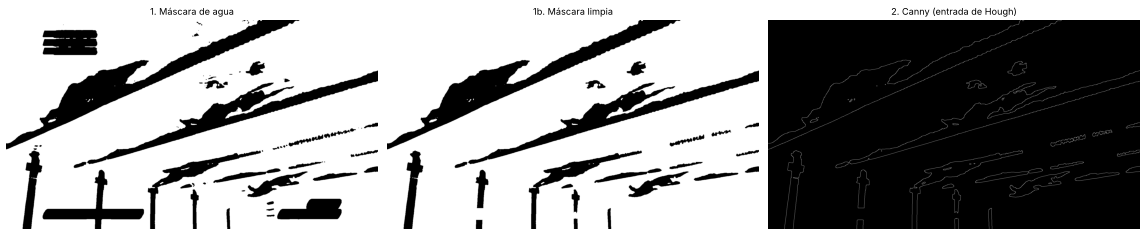

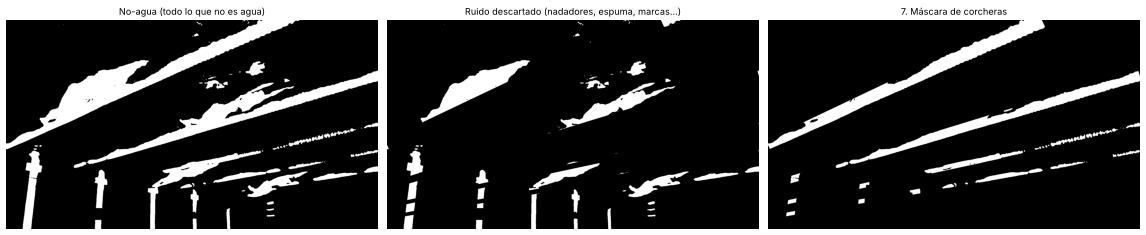

In [18]:
frame = frames["ILP_01295"]
r = delimitar_piscina(frame, segmentar_agua, GRAFICOS)
mostrar([r["agua"], r["limpia"], r["bordes"]], ["1. Máscara de agua", "1b. Máscara limpia", "2. Canny (entrada de Hough)"])
mostrar([r["no_agua"], r["ruido"], r["corcheras"]],
        ["No-agua (todo lo que no es agua)", "Ruido descartado (nadadores, espuma, marcas...)", "7. Máscara de corcheras"])

## Las 20 imágenes de ILP

De cada imagen, el resultado (sin agua, sin ruido, corcheras marcadas) queda en `output/delimitacion/ILP/` como `_resultado.jpg`. En `output/corcheras/ILP/` siguen la máscara de solo corcheras, su máscara binaria y las rectas sobre el frame.


In [19]:
SALIDA.mkdir(parents=True, exist_ok=True)
resumen = []
mosaico = []
for ruta in RUTAS:
    frame = cv2.imread(str(ruta))
    r = delimitar_piscina(frame, segmentar_agua, GRAFICOS)
    final = resultado(frame, r)
    dest = ROOT / "output" / "delimitacion" / VISTA
    dest.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(dest / f"{ruta.stem}_resultado.jpg"), final, [cv2.IMWRITE_JPEG_QUALITY, 90])
    cv2.imwrite(str(SALIDA / f"{ruta.stem}_corcheras.png"), solo(frame, r["corcheras"]))
    cv2.imwrite(str(SALIDA / f"{ruta.stem}_mascara_corcheras.png"), r["corcheras"])
    cv2.imwrite(str(SALIDA / f"{ruta.stem}_carriles.jpg"), dibujar(frame, r))
    v = vp_cartesiano(r["vp"]) if r["vp"] is not None else None
    resumen.append((ruta.stem, len(r["segmentos"]), int(r["inliers"].sum()), len(r["lineas"]),
                    0 if r["marcas"] is None else len(r["marcas"]),
                    "∞" if v is None or np.abs(v).max() > 1e4 else f"({v[0]:.0f}, {v[1]:.0f})"))
    mosaico.append((ruta.stem, solo(frame, r["no_agua"]), final))

print(f"{'imagen':<11}{'seg.':>6}{'→VP':>6}{'carriles':>10}{'marcas':>8}   VP")
for fila in resumen:
    print(f"{fila[0]:<11}{fila[1]:>6}{fila[2]:>6}{fila[3]:>10}{fila[4]:>8}   {fila[5]}")


imagen       seg.   →VP  carriles  marcas   VP
ILP_00185      80    66         6       0   (2303, 600)
ILP_00370     108    70         6       0   ∞
ILP_00555     132    65         3       0   (-1328, 1459)
ILP_00740     114    63         7      21   (-5222, 1078)
ILP_00925     109    93         4       0   (-1193, 1411)
ILP_01110     117    66         5       0   (2812, 1433)
ILP_01295      83    47         4      12   (-1335, 1254)
ILP_01480      85    42         6      14   (2803, 1374)
ILP_01665     121    69         8       0   (2663, 1467)
ILP_01850     130    67         7       0   (-695, 1334)
ILP_02035      83    57         6       9   (3258, 1129)
ILP_02220      67    55         6       0   (2443, 524)
ILP_02405     139    87         8       0   ∞
ILP_02590      95    71         6      12   (-906, 1255)
ILP_02775      94    32         4       0   (855, 1831)
ILP_02960      52    15         3       0   ∞
ILP_03145      34    12         3       0   (8391, 1026)
ILP_03330      7

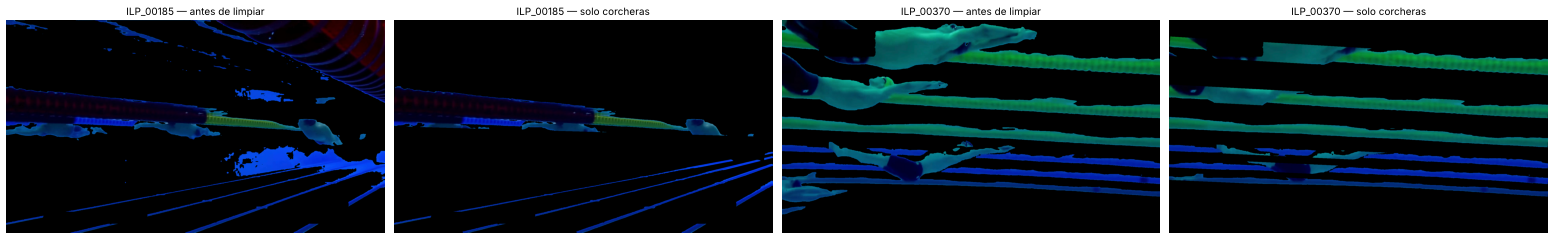

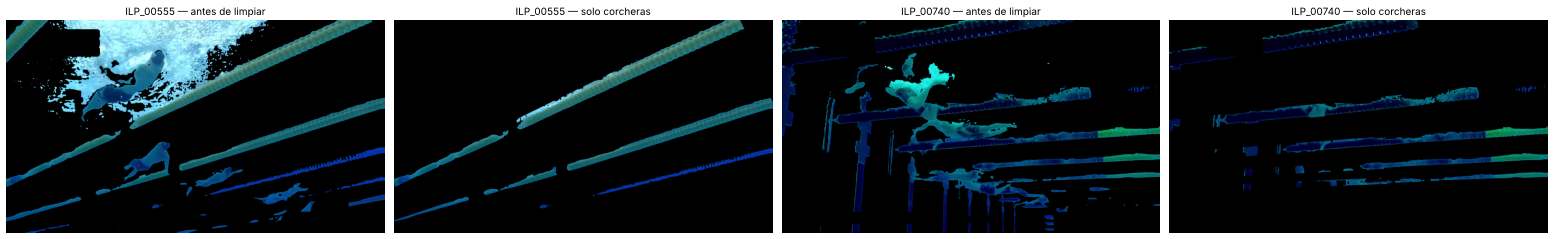

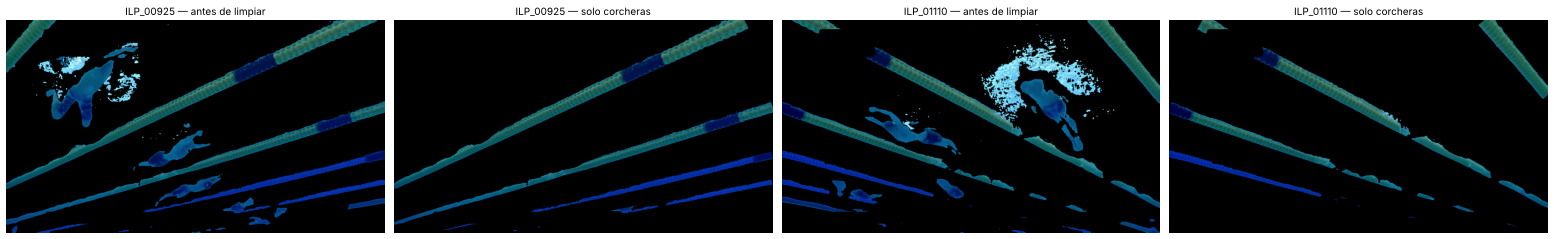

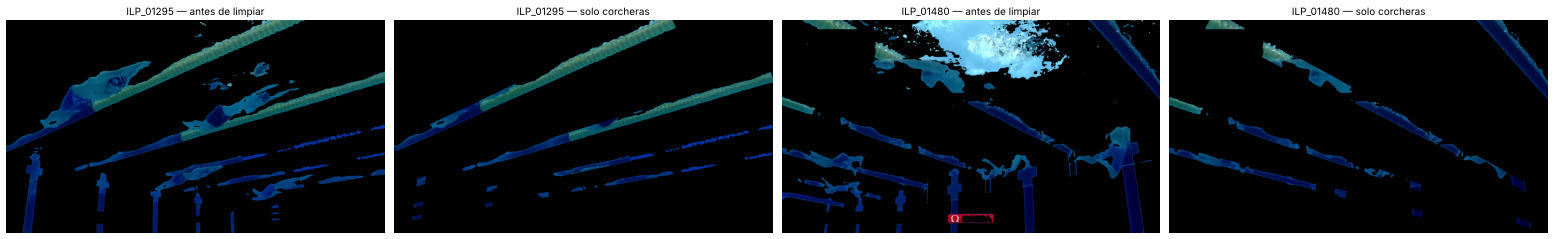

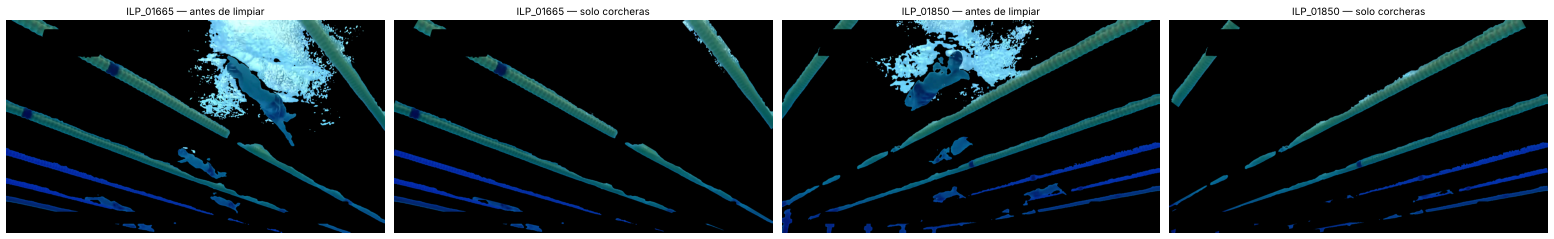

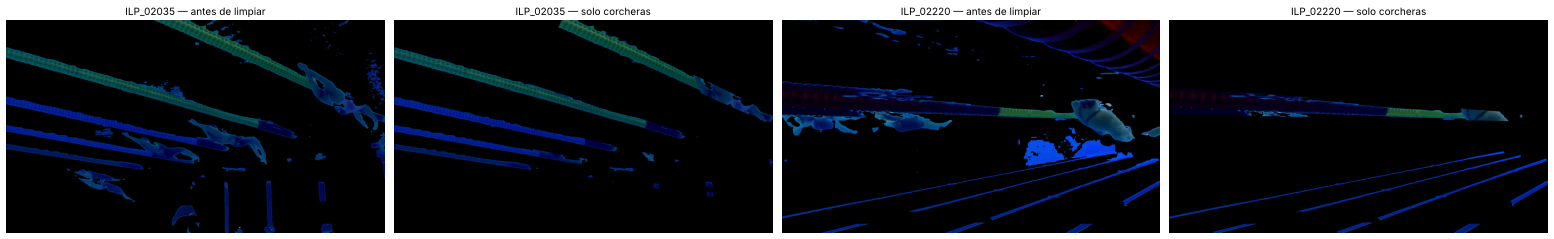

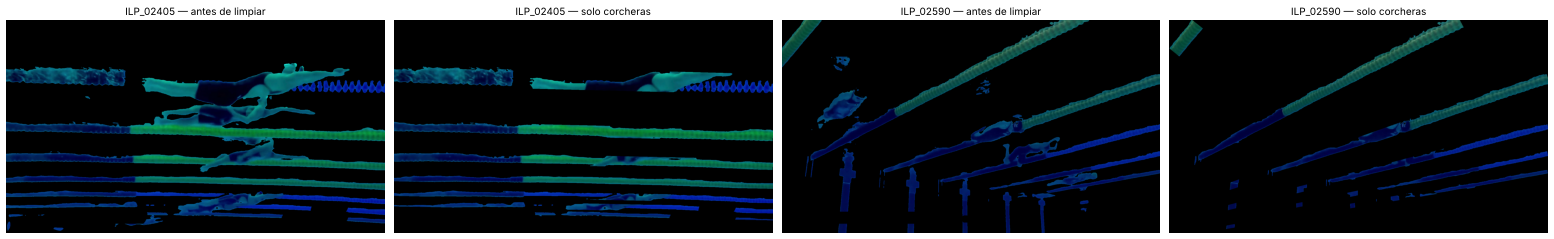

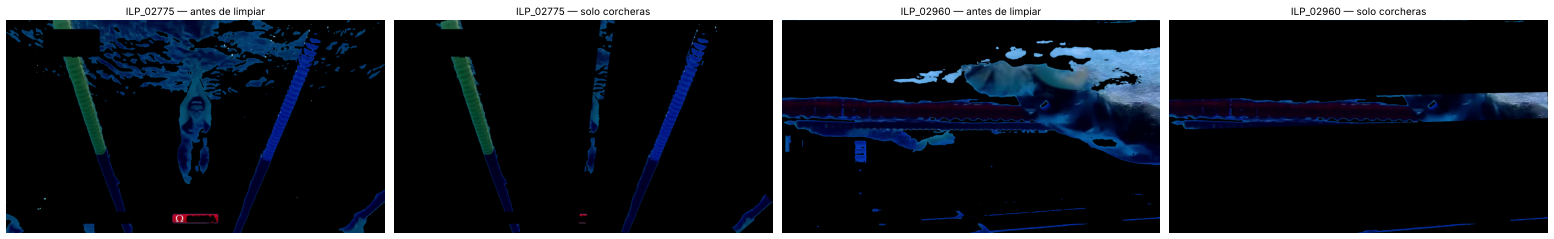

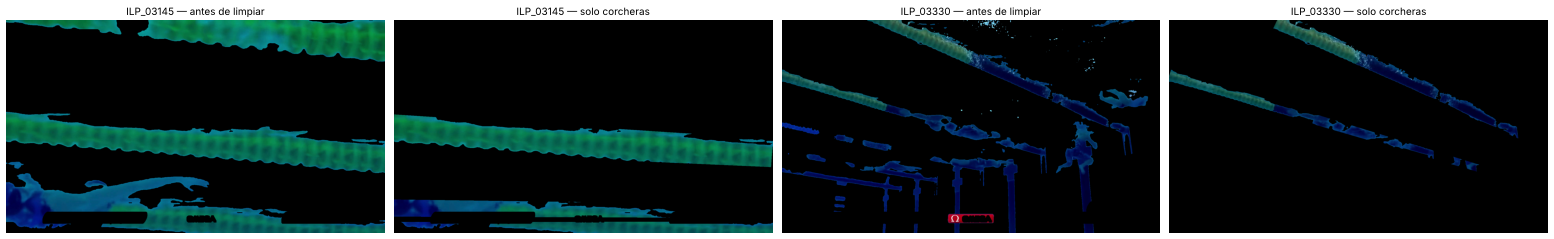

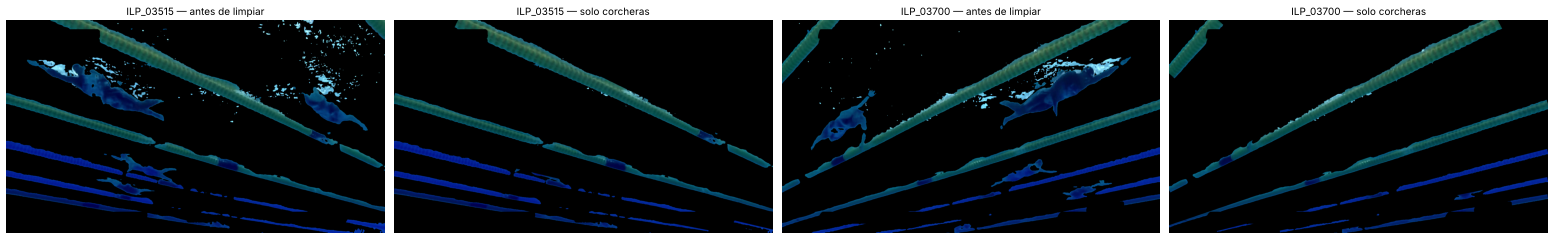

In [20]:
for i in range(0, len(mosaico), 2):
    fig, ax = plt.subplots(1, 4, figsize=(26, 4))
    for j, (nombre, antes, final) in enumerate(mosaico[i:i + 2]):
        ax[2 * j].imshow(rgb(antes)); ax[2 * j].set_title(f"{nombre} — antes de limpiar")
        ax[2 * j + 1].imshow(rgb(final)); ax[2 * j + 1].set_title(f"{nombre} — sin agua ni ruido")
    for a in ax:
        a.axis("off")
    plt.tight_layout(); plt.show()


## Observaciones

Con un filtro por ángulo no se puede decidir qué es carril en ILP. Hay tomas con las corcheras horizontales, otras en diagonal y otras casi verticales. Con el punto de fuga alcanza con ver si la recta apunta al mismo lugar que las demás. En las 20 imágenes, entre el 45% y el 90% de la longitud de los segmentos de Hough apunta a ese punto. El resto son contornos de nadadores, espuma y marcas.

La recta entre dos puntos, el cruce de dos rectas y el recorte contra el borde de la imagen son productos cruz. Un punto de fuga fuera de la foto se trata igual que uno en el infinito. Pasa en ILP_02405 y en ILP_02960.

Una banda de ancho fijo dejaba restos de corchera cerca de la cámara y se comía demasiado la parte lejana. Dividir el ancho por la distancia al punto de fuga lo deja en un solo número por recta, y la banda queda en cuña.

Las marcas de la pared salen como otra familia, entre lo que el RANSAC no usó para los carriles. Se ven en ILP_00740, 01295, 01480, 02035, 02590 y 03330. No apuntan al punto de fuga de los carriles, así que no entran en el resultado.

Los gráficos salen de los bordes que no se mueven. No hay coordenadas escritas a mano, así que en las otras vistas del mismo video debería servir igual.

Lo que no queda resuelto:

* Si un nadador cae justo dentro de la banda, esos píxeles se quedan como corchera. Se nota cuando la cámara va paralela a las corcheras y los nadadores también quedan paralelos, en ILP_00370 y en ILP_02405.
* Si una corchera está casi toda tapada por nadadores o por espuma, no llega al soporte mínimo y no aparece. Pasa con la corchera oscura de arriba en ILP_02405.
* Cuando hay pocas rectas salen solo 2 o 3 carriles. ILP_03145 está desenfocada y ILP_03330 tiene mucha espuma.

Para IL o ISL, `delimitar_piscina(frame, segmentar_agua, graficos)` no depende de ILP más que en la máscara. Se puede pasar `lambda f: dc.segmentar_agua(f, "IL")` y la máscara de gráficos armada con esas rutas. Lo que sí hay que volver a mirar es `gap_grupo` y `radio_perfil`, porque en esas vistas las corcheras se ven más delgadas.
